In [76]:
!pip install --upgrade binance-historical-data plotly -q
!pip install requests

In [77]:
import os
import warnings
import numpy as np
import pandas as pd
from binance_historical_data import BinanceDataDumper
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
warnings.filterwarnings('ignore')

In [78]:
# Define parameter ranges (as percentages)
a1_range = np.arange(0.001,0.01,0.005)  # 0.2%, 0.5%, 1%
a2_range = np.arange(0.01,0.05,0.03)  # 0.5%, 1%, 1.5%
trailing_sl_range = np.arange(0.001,0.01,0.005)  # 0.3%, 0.75%, 1.2%

In [79]:
data_frequency = "1d"
start_date = "2024-01-01"
end_date = "2025-07-01"
tickers =['BTCUSDT']




In [80]:
def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_list_all_trading_pairs()

def filter_usdt_tickers(tickers):
    exclude_keywords = ["UPUSDT", "DOWNUSDT", "BEARUSDT", "BULLUSDT"]
    return [ticker for ticker in tickers if ticker.endswith("USDT") and not any(ex in ticker for ex in exclude_keywords)]

def find_first_data_date(ticker):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_min_start_date_for_ticker(ticker)

def format_time(seconds):
    hours = int(seconds // 3600)
    minutes = int((seconds % 3600) // 60)
    secs = int(seconds % 60)
    return f"{hours:02d}:{minutes:02d}:{secs:02d}"

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data


In [81]:
download_ticker(tickers[0], start_date, end_date, data_frequency)
crypto_data = process_csv_files(tickers[0], data_frequency)


---> Found overall tickers: 594
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 1d
---> Start Date: 20240101
---> End Date: 20250701


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 2 tickers:
---> For BTCUSDT new data saved for: 0 months 0 days
---> For BTCUSD new data saved for: 0 months 0 days


In [82]:
data = crypto_data[['open_time','Open','High','Low', 'Close','volume']].reset_index(drop=True)
data.columns = ['timestamp','open','high','low', 'close','volume']
data

,timestamp,open,high,low,close,volume
0,2024-01-02,44179.55,45879.63,44148.34,44946.91,65146.40661
1,2024-01-03,44946.91,45500.00,40750.00,42845.23,81194.55173
2,2024-01-04,42845.23,44729.58,42613.77,44151.10,48038.06334
3,2024-01-05,44151.10,44357.46,42450.00,44145.11,48075.25327
4,2024-01-06,44145.12,44214.42,43397.05,43968.32,17835.06144
...,...,...,...,...,...,...
524,2025-06-26,107340.59,108272.45,106562.50,106947.06,10573.27279
525,2025-06-27,106947.06,107735.34,106356.76,107047.59,12232.44042
526,2025-06-28,107047.58,107577.75,106811.51,107296.79,3282.17352
527,2025-06-29,107296.79,108528.50,107172.52,108356.93,6831.73640


Parameter Sweep Test Results:
   a1_percent  a2_percent  trailing_sl_percent  total_trades  win_rate  \
4       0.006        0.01                0.001           262       0.0   
1       0.001        0.01                0.006           246       0.0   
5       0.006        0.01                0.006           246       0.0   
0       0.001        0.01                0.001           263       0.0   
3       0.001        0.04                0.006           246       0.0   
7       0.006        0.04                0.006           246       0.0   
6       0.006        0.04                0.001           262       0.0   
2       0.001        0.04                0.001           263       0.0   

   total_pct_return  final_unrealized_pnl  
4         -4.095035             -0.006271  
1         -4.167963             -0.001253  
5         -4.208810             -0.006271  
0         -4.318045             -0.001253  
3        -10.202806             -0.001253  
7        -10.209314             -0.0062

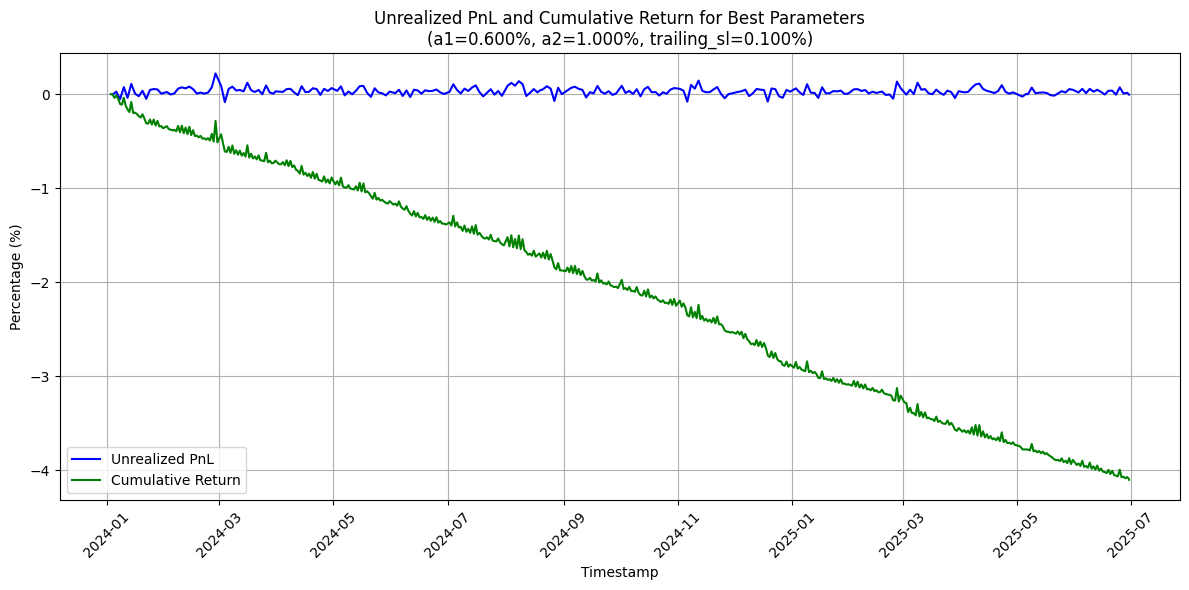

In [83]:
import pandas as pd
import numpy as np
from itertools import product
import matplotlib.pyplot as plt

def backtest_strategy(data, a1_percent, a2_percent, trailing_sl_percent):
    """
    Backtest trading strategy based on previous candle color with percentage-based returns.

    Parameters:
    - data: DataFrame with OHLC data (columns: timestamp, open, high, low, close)
    - a1_percent: Entry offset (percentage of previous candle close)
    - a2_percent: Fixed stop loss (percentage of previous candle close)
    - trailing_sl_percent: Trailing stop loss (percentage of previous candle close)

    Returns:
    - trades: DataFrame of trades with entry, exit, side, and percentage return
    - unrealized_pnl: DataFrame of unrealized PnL values over time
    - cumulative_return: DataFrame of cumulative return over time
    - summary: Dictionary with total trades, win rate, total percentage return, and final unrealized PnL
    """
    trades = []
    unrealized_pnl = []
    cumulative_return = []
    position = None
    entry_price = 0
    stop_loss = 0
    trailing_stop = 0
    cum_return = 0  # Tracks cumulative return from closed trades

    data = data.sort_values('timestamp').reset_index(drop=True)

    for i in range(1, len(data)):
        prev_candle = data.iloc[i-1]
        curr_candle = data.iloc[i]
        a1 = a1_percent * prev_candle['close']
        a2 = a2_percent * prev_candle['close']
        trailing_sl = trailing_sl_percent * prev_candle['close']

        is_green = prev_candle['close'] > prev_candle['open']

        # Calculate unrealized PnL and cumulative return for open position
        if position is not None:
            current_pnl = (curr_candle['close'] - entry_price) / entry_price if position == 'long' else \
                          (entry_price - curr_candle['close']) / entry_price
            unrealized_pnl.append({
                'timestamp': curr_candle['timestamp'],
                'unrealized_pnl': current_pnl
            })
            # Cumulative return = realized (from closed trades) + unrealized (from open position)
            cumulative_return.append({
                'timestamp': curr_candle['timestamp'],
                'cumulative_return': cum_return + current_pnl
            })
        else:
            # No open position, cumulative return remains the same
            cumulative_return.append({
                'timestamp': curr_candle['timestamp'],
                'cumulative_return': cum_return
            })

        # Entry logic
        if position is None:
            entry_level = (prev_candle['low'] + a1) if is_green else (prev_candle['high'] + a1)
            side = 'long' if is_green else 'short'

            if (side == 'long' and curr_candle['high'] >= entry_level) or \
               (side == 'short' and curr_candle['low'] <= entry_level):
                entry_price = entry_level
                position = side
                stop_loss = entry_price * (1 - a2_percent) if side == 'long' else entry_price * (1 + a2_percent)
                trailing_stop = entry_price * (1 - trailing_sl_percent) if side == 'long' else entry_price * (1 + trailing_sl_percent)

                trades.append({
                    'entry_time': curr_candle['timestamp'],
                    'entry_price': entry_price,
                    'side': side,
                    'stop_loss': stop_loss,
                    'trailing_stop': trailing_stop
                })

        # Exit logic
        elif position is not None:
            if position == 'long':
                trailing_stop = max(trailing_stop, curr_candle['close'] * (1 - trailing_sl_percent))

                if curr_candle['low'] <= stop_loss or curr_candle['low'] <= trailing_stop:
                    exit_price = min(stop_loss, trailing_stop, curr_candle['low'])
                    pct_return = (exit_price - entry_price) / entry_price
                    cum_return += pct_return  # Update cumulative return
                    trades[-1].update({
                        'exit_time': curr_candle['timestamp'],
                        'exit_price': exit_price,
                        'pct_return': pct_return
                    })
                    position = None

            elif position == 'short':
                trailing_stop = min(trailing_stop, curr_candle['close'] * (1 + trailing_sl_percent))

                if curr_candle['high'] >= stop_loss or curr_candle['high'] >= trailing_stop:
                    exit_price = max(stop_loss, trailing_stop, curr_candle['high'])
                    pct_return = (entry_price - exit_price) / entry_price
                    cum_return += pct_return  # Update cumulative return
                    trades[-1].update({
                        'exit_time': curr_candle['timestamp'],
                        'exit_price': exit_price,
                        'pct_return': pct_return
                    })
                    position = None

    # Calculate final unrealized PnL and cumulative return
    final_unrealized_pnl = 0
    if position is not None:
        final_close = data.iloc[-1]['close']
        final_unrealized_pnl = (final_close - entry_price) / entry_price if position == 'long' else \
                               (entry_price - final_close) / entry_price
        unrealized_pnl.append({
            'timestamp': data.iloc[-1]['timestamp'],
            'unrealized_pnl': final_unrealized_pnl
        })
        cumulative_return.append({
            'timestamp': data.iloc[-1]['timestamp'],
            'cumulative_return': cum_return + final_unrealized_pnl
        })
    else:
        cumulative_return.append({
            'timestamp': data.iloc[-1]['timestamp'],
            'cumulative_return': cum_return
        })

    trades_df = pd.DataFrame(trades)
    unrealized_pnl_df = pd.DataFrame(unrealized_pnl)
    cumulative_return_df = pd.DataFrame(cumulative_return)

    if not trades_df.empty:
        total_trades = len(trades_df)
        win_rate = len(trades_df[trades_df['pct_return'] > 0]) / total_trades
        total_pct_return = trades_df['pct_return'].sum()
    else:
        total_trades = 0
        win_rate = 0
        total_pct_return = 0

    return {
        'trades': trades_df,
        'unrealized_pnl': unrealized_pnl_df,
        'cumulative_return': cumulative_return_df,
        'summary': {
            'total_trades': total_trades,
            'win_rate': win_rate,
            'total_pct_return': total_pct_return,
            'final_unrealized_pnl': final_unrealized_pnl
        }
    }

def sweep_test_parameters(data, a1_range, a2_range, trailing_sl_range):
    """
    Perform a parameter sweep test for a1_percent, a2_percent, and trailing_sl_percent.

    Parameters:
    - data: DataFrame with OHLC data (columns: timestamp, open, high, low, close)
    - a1_range: List of a1_percent values to test (as decimals, e.g., 0.005 for 0.5%)
    - a2_range: List of a2_percent values to test (as decimals)
    - trailing_sl_range: List of trailing_sl_percent values to test (as decimals)

    Returns:
    - results_df: DataFrame with parameter combinations and their performance metrics
    - best_params: Best parameter set based on total_pct_return
    - best_unrealized_pnl: Unrealized PnL DataFrame for the best parameter set
    - best_cumulative_return: Cumulative return DataFrame for the best parameter set
    """
    results = []

    for a1_percent, a2_percent, trailing_sl_percent in product(a1_range, a2_range, trailing_sl_range):
        result = backtest_strategy(data, a1_percent, a2_percent, trailing_sl_percent)

        results.append({
            'a1_percent': a1_percent,
            'a2_percent': a2_percent,
            'trailing_sl_percent': trailing_sl_percent,
            'total_trades': result['summary']['total_trades'],
            'win_rate': result['summary']['win_rate'],
            'total_pct_return': result['summary']['total_pct_return'],
            'final_unrealized_pnl': result['summary']['final_unrealized_pnl']
        })

        # Store unrealized PnL and cumulative return for the current parameter set
        if not result['unrealized_pnl'].empty:
            result['unrealized_pnl']['a1_percent'] = a1_percent
            result['unrealized_pnl']['a2_percent'] = a2_percent
            result['unrealized_pnl']['trailing_sl_percent'] = trailing_sl_percent
            if 'all_unrealized_pnl' not in locals():
                all_unrealized_pnl = result['unrealized_pnl']
            else:
                all_unrealized_pnl = pd.concat([all_unrealized_pnl, result['unrealized_pnl']], ignore_index=True)

        if not result['cumulative_return'].empty:
            result['cumulative_return']['a1_percent'] = a1_percent
            result['cumulative_return']['a2_percent'] = a2_percent
            result['cumulative_return']['trailing_sl_percent'] = trailing_sl_percent
            if 'all_cumulative_return' not in locals():
                all_cumulative_return = result['cumulative_return']
            else:
                all_cumulative_return = pd.concat([all_cumulative_return, result['cumulative_return']], ignore_index=True)

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values('total_pct_return', ascending=False)

    # Get best parameter set
    best_params = results_df.iloc[0][['a1_percent', 'a2_percent', 'trailing_sl_percent']].to_dict()
    best_unrealized_pnl = all_unrealized_pnl[
        (all_unrealized_pnl['a1_percent'] == best_params['a1_percent']) &
        (all_unrealized_pnl['a2_percent'] == best_params['a2_percent']) &
        (all_unrealized_pnl['trailing_sl_percent'] == best_params['trailing_sl_percent'])
    ][['timestamp', 'unrealized_pnl']].copy()
    best_cumulative_return = all_cumulative_return[
        (all_cumulative_return['a1_percent'] == best_params['a1_percent']) &
        (all_cumulative_return['a2_percent'] == best_params['a2_percent']) &
        (all_cumulative_return['trailing_sl_percent'] == best_params['trailing_sl_percent'])
    ][['timestamp', 'cumulative_return']].copy()

    return results_df, best_params, best_unrealized_pnl, best_cumulative_return

# Example usage
if __name__ == "__main__":


    # Run sweep test
    results_df, best_params, best_unrealized_pnl, best_cumulative_return = sweep_test_parameters(data, a1_range, a2_range, trailing_sl_range)

    # Print results
    print("Parameter Sweep Test Results:")
    print(results_df)

    # Save results to CSV
    results_df.to_csv('sweep_test_results.csv', index=False)
    print("\nResults saved to 'sweep_test_results.csv'")

    # Plot unrealized PnL and cumulative return for the best parameter set
    if not best_unrealized_pnl.empty and not best_cumulative_return.empty:
        plt.figure(figsize=(12, 6))
        plt.plot(pd.to_datetime(best_unrealized_pnl['timestamp']), best_unrealized_pnl['unrealized_pnl'],
                 label='Unrealized PnL', color='blue')
        plt.plot(pd.to_datetime(best_cumulative_return['timestamp']), best_cumulative_return['cumulative_return'],
                 label='Cumulative Return', color='green')
        plt.title(f"Unrealized PnL and Cumulative Return for Best Parameters\n"
                  f"(a1={best_params['a1_percent']:.3%}, a2={best_params['a2_percent']:.3%}, "
                  f"trailing_sl={best_params['trailing_sl_percent']:.3%})")
        plt.xlabel('Timestamp')
        plt.ylabel('Percentage (%)')
        plt.legend()
        plt.grid(True)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig('best_pnl_and_return.png')
        # plt.close()
        print("\nUnrealized PnL and Cumulative Return plot saved to 'best_pnl_and_return.png'")
    else:
        print("\nNo data to plot for unrealized PnL or cumulative return for the best parameter set.")